<a href="https://colab.research.google.com/github/Fajtos/forecast-reconciliation/blob/main/lstm_validation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.9/67.9 kB 805.9 kB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.3/60.3 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 419.5/419.5 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 12.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.5/87.5 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 841.3/841.3 kB 27.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 34.0 MB/s eta 0:00:00
PyTorch version: 2.11.0+cpu
CUDA available: False
Mounted at /content/drive


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/rnn.py:1013: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.2 and num_layers=1
  super().__init__("LSTM", *args, **kwargs)
INFO:pytorch_lightning.utilities.rank_zero:GPU available: False, used: False
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Downloaded 516 days of data
Volatility range: 0.0255 to 1.0365

Generating LSTM forecasts...
Training 83 LSTM models...
  Progress: 0/83


/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/data.py:106: Total length of `list` across ranks is zero. Please make sure this was your intention.
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=10` reached.
INFO:pytorch_lightning.utilities.rank_zero:GPU available: False, used: False
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/lit

Output()

INFO:pytorch_lightning.utilities.rank_zero:GPU available: False, used: False
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


... (840 outputs left out)

Output()

INFO:pytorch_lightning.utilities.rank_zero:GPU available: False, used: False
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Output()

Generated forecasts for 83 origins

Raw LSTM Incoherence: 0.000036
Reconciled LSTM Incoherence: 0.000000
Reduction: 100.0%

Results saved to Google Drive


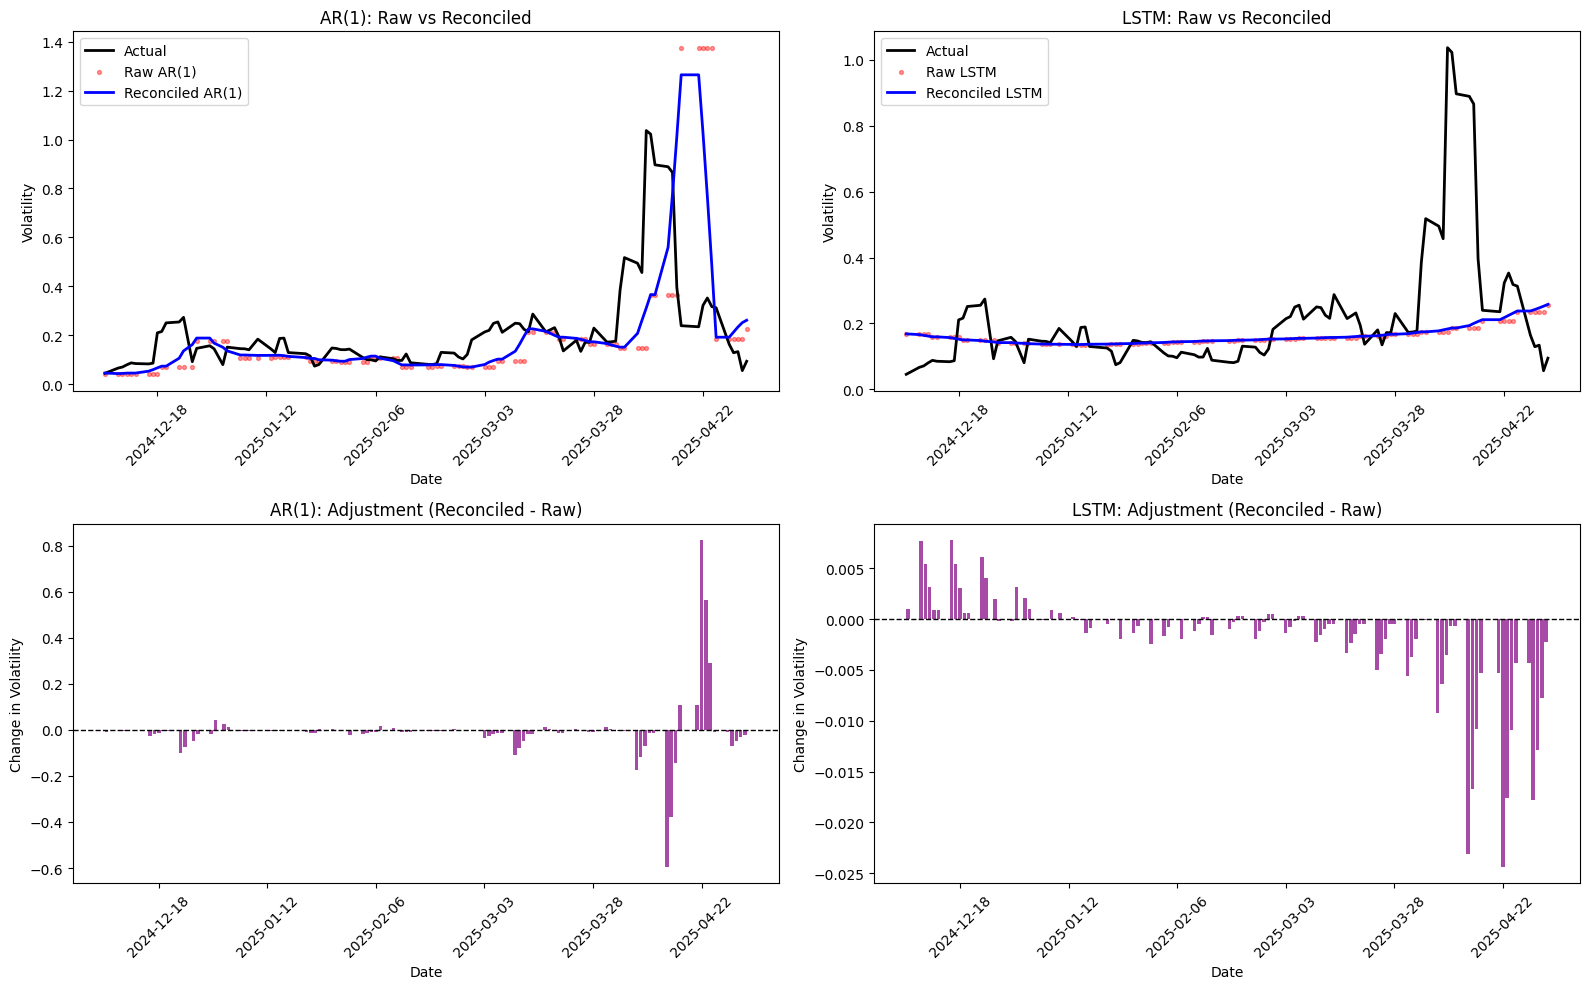

Figure saved as 'ar1_vs_lstm_comparison.png'


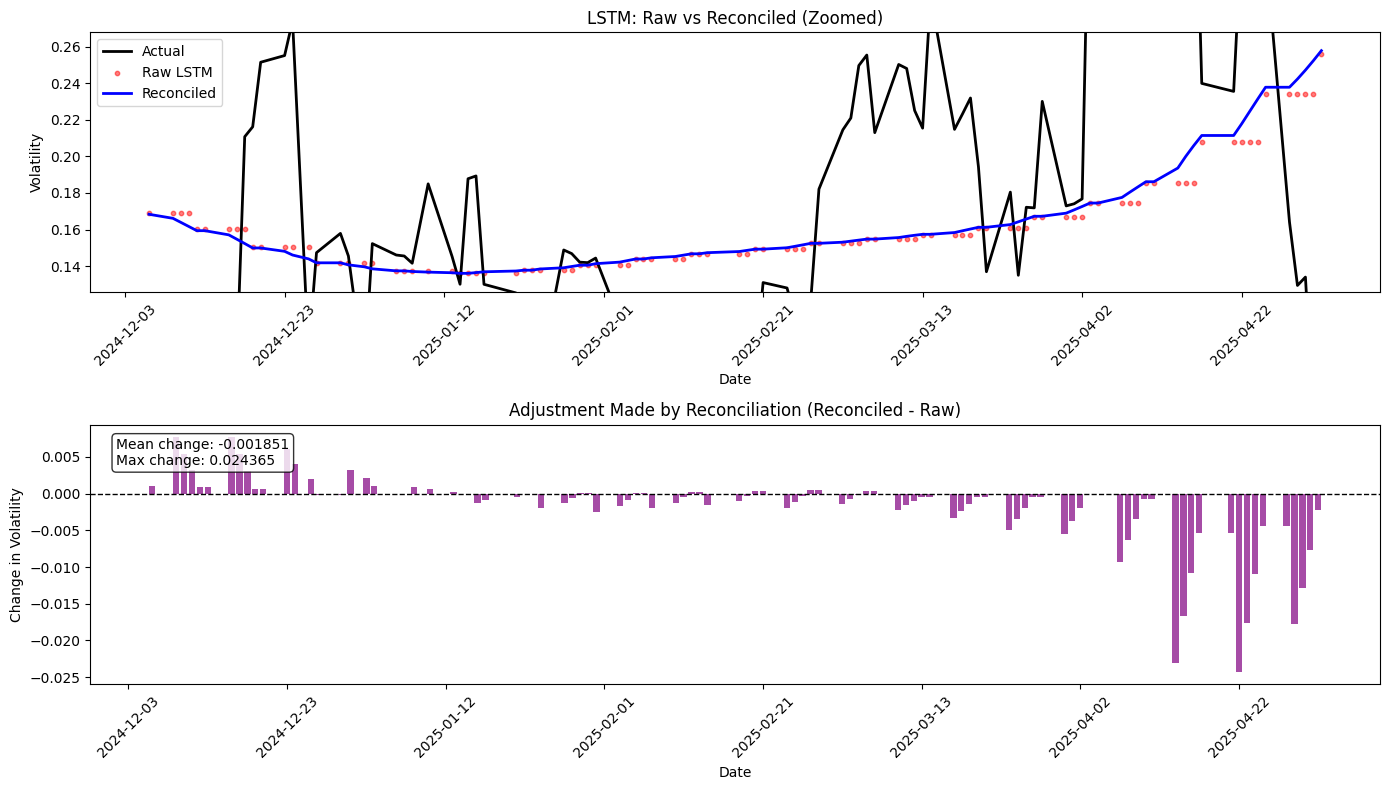

Figure saved as 'lstm_zoomed_adjustment.png'


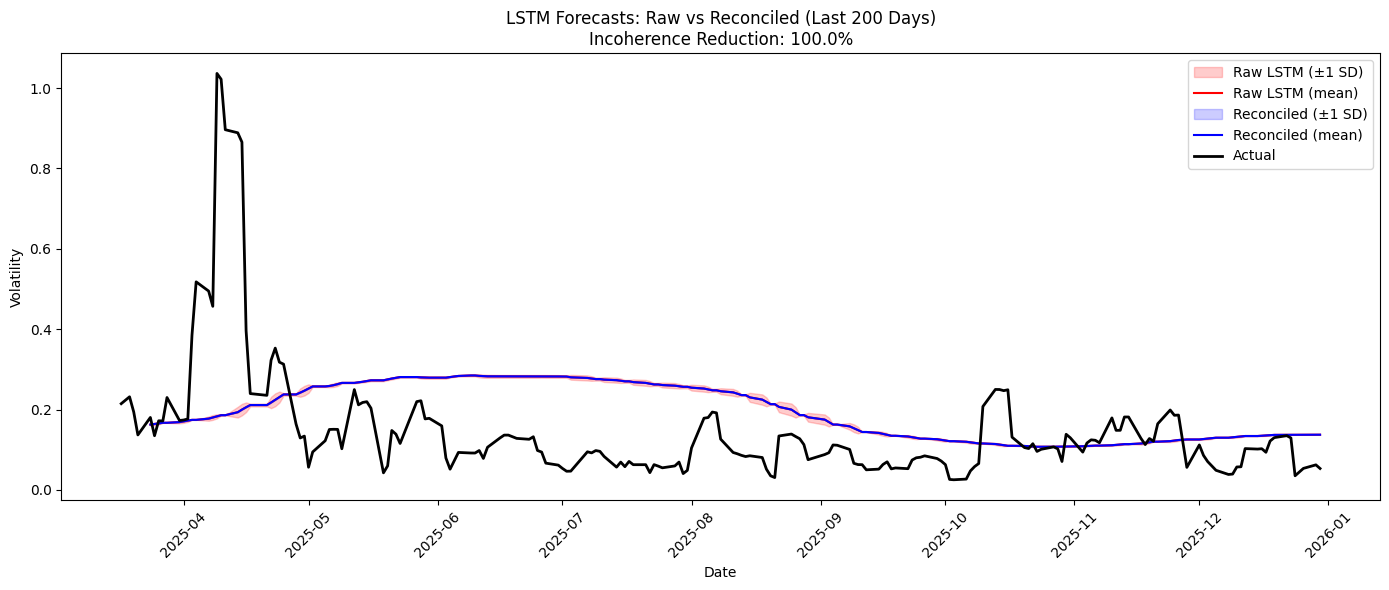

Figure saved as 'lstm_focused_view.png'


In [1]:
# ============================================================
# Bayesian Reconciliation of Multi-Step AI Forecasts
# LSTM Validation - Follow-up Analysis
# Author: Oluwatosin Bamidele Fajana
# Description: This script generates LSTM forecasts for SPY volatility,
#              applies diagonal reconciliation, and produces comparison figures.
# ============================================================

# CELL 1: SETUP AND INSTALLATION
!pip install yfinance pandas numpy matplotlib scikit-learn -q
!pip install "darts[torch]" -q

import torch
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from darts import TimeSeries
from darts.models import RNNModel
from google.colab import drive

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

drive.mount('/content/drive')

# ============================================================
# CELL 2: DOWNLOAD SPY DATA
# ============================================================

def download_spy_data():
    """Download SPY data and compute 5-day rolling volatility"""
    spy = yf.download(
        'SPY',
        start='2023-12-01',
        end='2025-12-31',
        progress=False,
        auto_adjust=True
    )
    spy['returns'] = spy['Close'].pct_change()
    spy['volatility'] = spy['returns'].rolling(window=5).std() * np.sqrt(252)
    spy = spy.dropna()
    return spy['volatility'].values, spy

y, spy_data = download_spy_data()
print(f"Downloaded {len(y)} days of data")
print(f"Volatility range: {y.min():.4f} to {y.max():.4f}")

# ============================================================
# CELL 3: LSTM FORECAST GENERATION
# ============================================================

def generate_lstm_forecasts(y, lookback=20, horizon=5, window_size=100,
                            stride=5, n_epochs=10):
    """
    Generate rolling LSTM forecasts using Darts with recursive multi-step prediction.

    Parameters:
    - y: univariate time series
    - lookback: number of past observations used as input
    - horizon: number of steps to forecast ahead
    - window_size: number of observations in each training window
    - stride: frequency of forecasting (every 'stride' days)
    - n_epochs: number of training epochs per model

    Returns:
    - forecast_matrix: T x H array of forecasts
    - origins: list of forecast origins
    """
    T = len(y)
    forecast_matrix = np.full((T, horizon), np.nan)
    origins = []
    series = TimeSeries.from_values(y)
    origins_idx = list(range(window_size, T - horizon + 1, stride))

    print(f"Training {len(origins_idx)} LSTM models...")

    for i, origin in enumerate(origins_idx):
        if i % 10 == 0:
            print(f"  Progress: {i}/{len(origins_idx)}")

        train_series = series[origin - window_size:origin]

        # Darts RNNModel uses default hidden size
        model = RNNModel(
            model="LSTM",
            input_chunk_length=lookback,
            output_chunk_length=1,
            n_epochs=n_epochs,
            batch_size=32,
            dropout=0.2,
            random_state=42,
            pl_trainer_kwargs={"accelerator": "gpu" if torch.cuda.is_available() else "cpu"}
        )

        model.fit(train_series, verbose=False)

        # Recursive multi-step forecasting
        current_vals = train_series[-lookback:].values().flatten().tolist()
        forecasts = []

        for h in range(horizon):
            current_input = TimeSeries.from_values(current_vals)
            pred = model.predict(n=1, series=current_input)
            pred_value = pred.values().flatten()[0]
            forecasts.append(pred_value)
            current_vals = current_vals[1:] + [pred_value]

        forecast_matrix[origin:origin+horizon, :] = forecasts
        origins.append(origin)

    return forecast_matrix, origins

print("\nGenerating LSTM forecasts...")
forecast_matrix, origins = generate_lstm_forecasts(
    y=y, lookback=20, horizon=5, window_size=100, stride=5, n_epochs=10
)
print(f"Generated forecasts for {len(origins)} origins")

# ============================================================
# CELL 4: RECONCILIATION FUNCTIONS
# ============================================================

def compute_incoherence(forecast_matrix):
    """
    Compute the temporal incoherence metric I.
    Measures the average squared disagreement among forecasts targeting the same future time.
    """
    T, H = forecast_matrix.shape
    total_sse = 0
    count = 0

    for t in range(H, T):
        all_forecasts = []
        for origin in range(max(0, t-H+1), min(t, T-H+1)):
            h = t - origin
            if h < H and h >= 0 and not np.isnan(forecast_matrix[origin, h]):
                all_forecasts.append(forecast_matrix[origin, h])

        if len(all_forecasts) > 1:
            for i in range(len(all_forecasts)):
                for j in range(i+1, len(all_forecasts)):
                    total_sse += (all_forecasts[i] - all_forecasts[j])**2
                    count += 1

    return total_sse / count if count > 0 else 0

def diagonal_reconciliation(forecast_matrix):
    """
    Simple diagonal reconciliation: replace each forecast with the average
    of all forecasts targeting the same future time.
    This is used for visualization purposes.
    """
    T, H = forecast_matrix.shape
    reconciled = np.full((T, H), np.nan)

    for t in range(H, T):
        all_forecasts = []
        for origin in range(max(0, t-H+1), min(t, T-H+1)):
            h = t - origin
            if h < H and h >= 0 and not np.isnan(forecast_matrix[origin, h]):
                all_forecasts.append(forecast_matrix[origin, h])

        if all_forecasts:
            avg = np.mean(all_forecasts)
            for origin in range(max(0, t-H+1), min(t, T-H+1)):
                h = t - origin
                if h < H and h >= 0 and not np.isnan(forecast_matrix[origin, h]):
                    reconciled[origin, h] = avg

    return reconciled

# ============================================================
# CELL 5: APPLY RECONCILIATION AND COMPUTE METRICS
# ============================================================

raw_incoherence = compute_incoherence(forecast_matrix)
print(f"\nRaw LSTM Incoherence: {raw_incoherence:.6f}")

reconciled_matrix = diagonal_reconciliation(forecast_matrix)
reconciled_incoherence = compute_incoherence(reconciled_matrix)
print(f"Reconciled LSTM Incoherence: {reconciled_incoherence:.6f}")
print(f"Reduction: {(1 - reconciled_incoherence/raw_incoherence)*100:.1f}%")

# ============================================================
# CELL 6: SAVE RESULTS TO GOOGLE DRIVE
# ============================================================

np.save('/content/drive/MyDrive/lstm_forecast_matrix.npy', forecast_matrix)
np.save('/content/drive/MyDrive/lstm_reconciled_matrix.npy', reconciled_matrix)
np.save('/content/drive/MyDrive/lstm_actual_values.npy', y)
print("\nResults saved to Google Drive")

# ============================================================
# CELL 7: SIDE-BY-SIDE COMPARISON (AR(1) vs LSTM)
# ============================================================

# Load AR(1) matrices if available
try:
    ar1_forecast_matrix = np.load('/content/drive/MyDrive/ar1_forecast_matrix.npy')
    ar1_reconciled_matrix = np.load('/content/drive/MyDrive/ar1_reconciled_matrix.npy')
    ar1_available = True
except FileNotFoundError:
    ar1_available = False
    print("AR(1) matrices not found. Only LSTM panels will be shown.")

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
focus_start = 250
focus_end = 350
dates_subset = spy_data.index[focus_start:focus_end]

# LEFT COLUMN: AR(1)
ax1 = axes[0, 0]
ax1.plot(dates_subset, y[focus_start:focus_end], 'k-', linewidth=2, label='Actual')

if ar1_available:
    ar1_raw_t, ar1_raw_y, ar1_recon_t, ar1_recon_y = [], [], [], []
    for t in range(focus_start, focus_end):
        for origin in range(max(0, t-5+1), min(t, len(y)-5+1)):
            h = t - origin
            if h < 5 and h >= 0:
                if not np.isnan(ar1_forecast_matrix[origin, h]):
                    ar1_raw_t.append(t)
                    ar1_raw_y.append(ar1_forecast_matrix[origin, h])
                    break
        for origin in range(max(0, t-5+1), min(t, len(y)-5+1)):
            h = t - origin
            if h < 5 and h >= 0:
                if not np.isnan(ar1_reconciled_matrix[origin, h]):
                    ar1_recon_t.append(t)
                    ar1_recon_y.append(ar1_reconciled_matrix[origin, h])
                    break
    if ar1_raw_t:
        ax1.scatter(dates_subset[:len(ar1_raw_t)], ar1_raw_y, color='red', s=8, alpha=0.4, label='Raw AR(1)')
    if ar1_recon_t:
        ax1.plot(dates_subset[:len(ar1_recon_t)], ar1_recon_y, 'b-', linewidth=2, label='Reconciled AR(1)')
else:
    ax1.text(0.5, 0.5, 'AR(1) matrices not loaded', horizontalalignment='center', transform=ax1.transAxes)

ax1.set_title('AR(1): Raw vs Reconciled')
ax1.set_xlabel('Date')
ax1.set_ylabel('Volatility')
ax1.legend()
ax1.xaxis.set_major_locator(plt.MaxNLocator(8))
plt.setp(ax1.xaxis.get_majorticklabels(), rotation=45)

ax2 = axes[1, 0]
if ar1_available:
    ar1_diff, ar1_diff_times = [], []
    for t in range(focus_start, focus_end):
        raw_val = recon_val = None
        for origin in range(max(0, t-5+1), min(t, len(y)-5+1)):
            h = t - origin
            if h < 5 and h >= 0:
                if not np.isnan(ar1_forecast_matrix[origin, h]):
                    raw_val = ar1_forecast_matrix[origin, h]
                if not np.isnan(ar1_reconciled_matrix[origin, h]):
                    recon_val = ar1_reconciled_matrix[origin, h]
        if raw_val is not None and recon_val is not None:
            ar1_diff.append(recon_val - raw_val)
            ar1_diff_times.append(t)
    if ar1_diff_times:
        ax2.bar(dates_subset[:len(ar1_diff_times)], ar1_diff, width=0.8, color='purple', alpha=0.7)
        ax2.axhline(y=0, color='black', linestyle='--', linewidth=1)
else:
    ax2.text(0.5, 0.5, 'AR(1) matrices not loaded', horizontalalignment='center', transform=ax2.transAxes)

ax2.set_title('AR(1): Adjustment (Reconciled - Raw)')
ax2.set_xlabel('Date')
ax2.set_ylabel('Change in Volatility')
ax2.xaxis.set_major_locator(plt.MaxNLocator(8))
plt.setp(ax2.xaxis.get_majorticklabels(), rotation=45)

# RIGHT COLUMN: LSTM
ax3 = axes[0, 1]
ax3.plot(dates_subset, y[focus_start:focus_end], 'k-', linewidth=2, label='Actual')

lstm_raw_t, lstm_raw_y, lstm_recon_t, lstm_recon_y = [], [], [], []
for t in range(focus_start, focus_end):
    for origin in range(max(0, t-5+1), min(t, len(y)-5+1)):
        h = t - origin
        if h < 5 and h >= 0:
            if not np.isnan(forecast_matrix[origin, h]):
                lstm_raw_t.append(t)
                lstm_raw_y.append(forecast_matrix[origin, h])
                break
    for origin in range(max(0, t-5+1), min(t, len(y)-5+1)):
        h = t - origin
        if h < 5 and h >= 0:
            if not np.isnan(reconciled_matrix[origin, h]):
                lstm_recon_t.append(t)
                lstm_recon_y.append(reconciled_matrix[origin, h])
                break

if lstm_raw_t:
    ax3.scatter(dates_subset[:len(lstm_raw_t)], lstm_raw_y, color='red', s=8, alpha=0.4, label='Raw LSTM')
if lstm_recon_t:
    ax3.plot(dates_subset[:len(lstm_recon_t)], lstm_recon_y, 'b-', linewidth=2, label='Reconciled LSTM')

ax3.set_title('LSTM: Raw vs Reconciled')
ax3.set_xlabel('Date')
ax3.set_ylabel('Volatility')
ax3.legend()
ax3.xaxis.set_major_locator(plt.MaxNLocator(8))
plt.setp(ax3.xaxis.get_majorticklabels(), rotation=45)

ax4 = axes[1, 1]
lstm_diff, lstm_diff_times = [], []
for t in range(focus_start, focus_end):
    raw_val = recon_val = None
    for origin in range(max(0, t-5+1), min(t, len(y)-5+1)):
        h = t - origin
        if h < 5 and h >= 0:
            if not np.isnan(forecast_matrix[origin, h]):
                raw_val = forecast_matrix[origin, h]
            if not np.isnan(reconciled_matrix[origin, h]):
                recon_val = reconciled_matrix[origin, h]
    if raw_val is not None and recon_val is not None:
        lstm_diff.append(recon_val - raw_val)
        lstm_diff_times.append(t)

if lstm_diff_times:
    ax4.bar(dates_subset[:len(lstm_diff_times)], lstm_diff, width=0.8, color='purple', alpha=0.7)
    ax4.axhline(y=0, color='black', linestyle='--', linewidth=1)

ax4.set_title('LSTM: Adjustment (Reconciled - Raw)')
ax4.set_xlabel('Date')
ax4.set_ylabel('Change in Volatility')
ax4.xaxis.set_major_locator(plt.MaxNLocator(8))
plt.setp(ax4.xaxis.get_majorticklabels(), rotation=45)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/ar1_vs_lstm_comparison.png', dpi=150)
plt.show()
print("Figure saved as 'ar1_vs_lstm_comparison.png'")

# ============================================================
# CELL 8: ZOOMED VIEW OF LSTM RECONCILIATION
# ============================================================

fig, axes = plt.subplots(2, 1, figsize=(14, 8))
focus_start = 250
focus_end = 350
dates_subset = spy_data.index[focus_start:focus_end]

ax1 = axes[0]
ax1.plot(dates_subset, y[focus_start:focus_end], 'k-', linewidth=2, label='Actual')

raw_t, raw_y, recon_t, recon_y = [], [], [], []
for t in range(focus_start, focus_end):
    for origin in range(max(0, t-5+1), min(t, len(y)-5+1)):
        h = t - origin
        if h < 5 and h >= 0:
            if not np.isnan(forecast_matrix[origin, h]):
                raw_t.append(t)
                raw_y.append(forecast_matrix[origin, h])
                break
    for origin in range(max(0, t-5+1), min(t, len(y)-5+1)):
        h = t - origin
        if h < 5 and h >= 0:
            if not np.isnan(reconciled_matrix[origin, h]):
                recon_t.append(t)
                recon_y.append(reconciled_matrix[origin, h])
                break

if raw_t:
    ax1.scatter(dates_subset[:len(raw_t)], raw_y, color='red', s=10, alpha=0.5, label='Raw LSTM')
if recon_t:
    ax1.plot(dates_subset[:len(recon_t)], recon_y, 'b-', linewidth=2, label='Reconciled')

y_min = min(np.min(raw_y) if raw_y else 0, np.min(recon_y) if recon_y else 0) - 0.01
y_max = max(np.max(raw_y) if raw_y else 1, np.max(recon_y) if recon_y else 1) + 0.01
ax1.set_ylim(y_min, y_max)

ax1.set_title('LSTM: Raw vs Reconciled (Zoomed)')
ax1.set_xlabel('Date')
ax1.set_ylabel('Volatility')
ax1.legend()
ax1.xaxis.set_major_locator(plt.MaxNLocator(10))
plt.setp(ax1.xaxis.get_majorticklabels(), rotation=45)

ax2 = axes[1]
diff_values, diff_times = [], []
for t in range(focus_start, focus_end):
    raw_val = recon_val = None
    for origin in range(max(0, t-5+1), min(t, len(y)-5+1)):
        h = t - origin
        if h < 5 and h >= 0:
            if not np.isnan(forecast_matrix[origin, h]):
                raw_val = forecast_matrix[origin, h]
            if not np.isnan(reconciled_matrix[origin, h]):
                recon_val = reconciled_matrix[origin, h]
    if raw_val is not None and recon_val is not None:
        diff_values.append(recon_val - raw_val)
        diff_times.append(t)

if diff_times:
    ax2.bar(dates_subset[:len(diff_times)], diff_values, width=0.8, color='purple', alpha=0.7)
    ax2.axhline(y=0, color='black', linestyle='--', linewidth=1)
    ax2.set_title('Adjustment Made by Reconciliation (Reconciled - Raw)')
    ax2.set_xlabel('Date')
    ax2.set_ylabel('Change in Volatility')
    ax2.xaxis.set_major_locator(plt.MaxNLocator(10))
    plt.setp(ax2.xaxis.get_majorticklabels(), rotation=45)

    mean_change = np.mean(diff_values)
    max_change = np.max(np.abs(diff_values))
    ax2.text(0.02, 0.95, f'Mean change: {mean_change:.6f}\nMax change: {max_change:.6f}',
             transform=ax2.transAxes, verticalalignment='top',
             bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/lstm_zoomed_adjustment.png', dpi=150)
plt.show()
print("Figure saved as 'lstm_zoomed_adjustment.png'")

# ============================================================
# CELL 9: ALTERNATIVE VIEW WITH SHADED BANDS
# ============================================================

fig, ax = plt.subplots(figsize=(14, 6))
focus_start = max(0, len(y) - 200)
dates = spy_data.index
target_times = range(focus_start + 5, len(y), 1)
raw_forecasts_at_t, recon_forecasts_at_t = [], []

for t in target_times:
    raw_vals = []
    for origin in range(max(0, t-5+1), min(t, len(y)-5+1)):
        h = t - origin
        if h < 5 and h >= 0 and not np.isnan(forecast_matrix[origin, h]):
            raw_vals.append(forecast_matrix[origin, h])
    if raw_vals:
        raw_forecasts_at_t.append((t, np.mean(raw_vals), np.std(raw_vals)))

    recon_vals = []
    for origin in range(max(0, t-5+1), min(t, len(y)-5+1)):
        h = t - origin
        if h < 5 and h >= 0 and not np.isnan(reconciled_matrix[origin, h]):
            recon_vals.append(reconciled_matrix[origin, h])
    if recon_vals:
        recon_forecasts_at_t.append((t, np.mean(recon_vals), np.std(recon_vals)))

if raw_forecasts_at_t and recon_forecasts_at_t:
    raw_times = [x[0] for x in raw_forecasts_at_t]
    raw_means = [x[1] for x in raw_forecasts_at_t]
    raw_stds = [x[2] for x in raw_forecasts_at_t]
    recon_times = [x[0] for x in recon_forecasts_at_t]
    recon_means = [x[1] for x in recon_forecasts_at_t]
    recon_stds = [x[2] for x in recon_forecasts_at_t]

    ax.fill_between(dates[raw_times],
                    np.array(raw_means) - np.array(raw_stds),
                    np.array(raw_means) + np.array(raw_stds),
                    color='red', alpha=0.2, label='Raw LSTM (±1 SD)')
    ax.plot(dates[raw_times], raw_means, 'r-', linewidth=1.5, label='Raw LSTM (mean)')
    ax.fill_between(dates[recon_times],
                    np.array(recon_means) - np.array(recon_stds),
                    np.array(recon_means) + np.array(recon_stds),
                    color='blue', alpha=0.2, label='Reconciled (±1 SD)')
    ax.plot(dates[recon_times], recon_means, 'b-', linewidth=1.5, label='Reconciled (mean)')
    ax.plot(dates[focus_start:], y[focus_start:], 'k-', linewidth=2, label='Actual')

    ax.set_xlabel('Date')
    ax.set_ylabel('Volatility')
    ax.set_title(f'LSTM Forecasts: Raw vs Reconciled (Last 200 Days)\nIncoherence Reduction: {(1 - reconciled_incoherence/raw_incoherence)*100:.1f}%')
    ax.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig('/content/drive/MyDrive/lstm_focused_view.png', dpi=150)
    plt.show()
    print("Figure saved as 'lstm_focused_view.png'")
else:
    print("Not enough data for focused view.")